# Valuing the option to store maize in Uasin-Gishu

**Erdős Institute — Quantitative Methods in Finance, Fall 2026 — course project**

**Question.** A Uasin-Gishu farmer holding maize after the October–December harvest can sell
now or store it (in agriBORA's certified Eldoret warehouse, or on the farm) and sell in any
later month. What is the option to delay the sale worth, what month-by-month rule captures
it, and does that rule beat selling at harvest on real Eldoret prices after realistic costs?

Maize in Kenya cannot be hedged (no exchange-traded maize futures), so the decision uses the
**real-world seasonal drift** of prices rather than risk-neutral pricing. The plan, inputs and
sources are in [`docs/agribora_worksheet.md`](docs/agribora_worksheet.md).

| Part | Steps | Status |
|---|---|---|
| Data, seasonal cycle, seasonal drift, volatility and GBM checks | 1–4 | this notebook |
| Forecast check, option value, Monte Carlo check, backtest, sensitivities | 5–9 | next |

All prices are **nominal** KSh per kg (wholesale, Eldoret). The loan rate used for discounting
later (≈ 15%/yr) is also nominal, so a nominal drift is the consistent choice; inflation then
sits inside the drift rather than needing a CPI series.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from scipy import stats
from scipy.optimize import least_squares

import quantkit as qk

sys.path.insert(0, "figures")
import seasonality as season      # tests used for figures/seasonality_uasin_gishu_vs_nairobi.png
%matplotlib inline

rng = np.random.default_rng(2026)

# chart styling (same palette as figures/)
SURF, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "axes.edgecolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.labelcolor": INK2,
                     "figure.dpi": 110})
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

## Step 1 — Load and inspect the price series (Lecture 3a)

`data/processed/wfp_monthly_wholesale.csv` is built by `data/make_data.py` from WFP market
monitoring (Eldoret town, 2006–2025) with five gaps filled from KAMIS Eldoret Main Market,
which matches WFP where both exist. See `data/README.md` for every splice.

In [2]:
raw = pd.read_csv("data/processed/wfp_monthly_wholesale.csv")
ug = raw[raw.county == "Uasin-Gishu"].copy()
ug["month"] = pd.PeriodIndex(ug.month, freq="M")
ug = ug.set_index("month")
price = ug.wholesale_kes_per_kg                     # nominal KSh/kg, NaN = no observation

print(f"{price.index.min()} -> {price.index.max()}: {price.notna().sum()} of {len(price)} months observed")
print("missing:", [str(m) for m in price[price.isna()].index])
print("\nsource of each month:")
print(ug.source.value_counts().to_string())
price.describe().round(1)

2006-01 -> 2025-06: 225 of 234 months observed
missing: ['2020-04', '2020-05', '2023-12', '2024-01', '2024-10', '2024-11', '2024-12', '2025-01', '2025-03']

source of each month:
source
WFP Eldoret, Maize per kg                            173
WFP Eldoret, Maize (white, dry) per 90 kg / 90        42
missing                                                9
WFP Eldoret, Maize (white) per 90 kg / 90              5
KAMIS Eldoret Main Market (Zindi), monthly median      5


count    225.0
mean      31.1
std       15.1
min       10.4
25%       22.0
50%       29.2
75%       35.9
max       90.4
Name: wholesale_kes_per_kg, dtype: float64

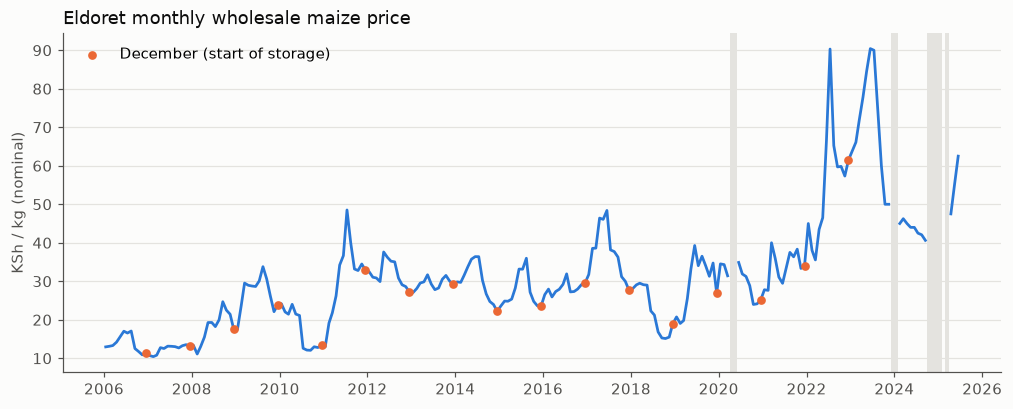

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
t = price.index.to_timestamp() + pd.Timedelta(days=14)
for m in price[price.isna()].index:                  # grey = no price that month
    d = m.to_timestamp() + pd.Timedelta(days=14)
    ax.axvspan(d - pd.Timedelta(days=15), d + pd.Timedelta(days=15), color=GRID, lw=0, zorder=0)
ax.plot(t, price.values, color=BLUE, lw=1.8)
# harvest-window lows: mark each December
dec = price[(price.index.month == 12)].dropna()
ax.scatter(dec.index.to_timestamp() + pd.Timedelta(days=14), dec.values, s=22, color=ORANGE,
           zorder=3, label="December (start of storage)")
ax.set_ylabel("KSh / kg (nominal)")
ax.set_title("Eldoret monthly wholesale maize price", loc="left", color=INK)
ax.xaxis.set_major_locator(mdates.YearLocator(2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(frameon=False, loc="upper left"); ax.grid(axis="x", visible=False)
plt.show()

**What to note.** Prices trend up (≈ 13 → 35 KSh/kg over 2006–2021, roughly Kenyan inflation),
swing seasonally every year, and spike in 2022–23 (peaks ≈ 90 KSh/kg in July 2022 and June 2023,
confirmed by KAMIS). Everything below is estimated on the **full series, 2006-01 → 2025-06**.
The 2022–23 seasons are 2 of 17; how much of storage's value comes from them is answered
season by season in the Step 8 backtest.

Monthly log returns $r_t = \log(P_t / P_{t-1})$ are used throughout. A return is only defined
when **both** consecutive months are observed; returns across a missing month are dropped
rather than counted as a one-month move.

In [4]:
r = np.log(price).diff().dropna()                    # NaN wherever either month is missing
r.name = "log_return"
full = pd.period_range(r.index.min(), r.index.max(), freq="M")
print(f"{len(r)} monthly returns, {r.index.min()} -> {r.index.max()}")

220 monthly returns, 2006-02 -> 2025-06


## Step 2 — The seasonal cycle (Lecture 8)

If prices do not rise predictably after harvest, there is no reason to store. Each season is
followed from December to November and measured against its own December–January (harvest)
price level. Then four tests from `figures/seasonality.py`:

* **Kruskal–Wallis / ANOVA:** do the 12 calendar months have different mean returns?
* **Annual cycle + random-phase permutation test:** fit one sine wave to the returns; compare
  its size with 5,000 reshuffles in which each year is rotated by its own random number of
  months (this destroys any timing shared across years but keeps each year's returns);
* **Sign test:** was the May–July price above the December–January level more often than chance?

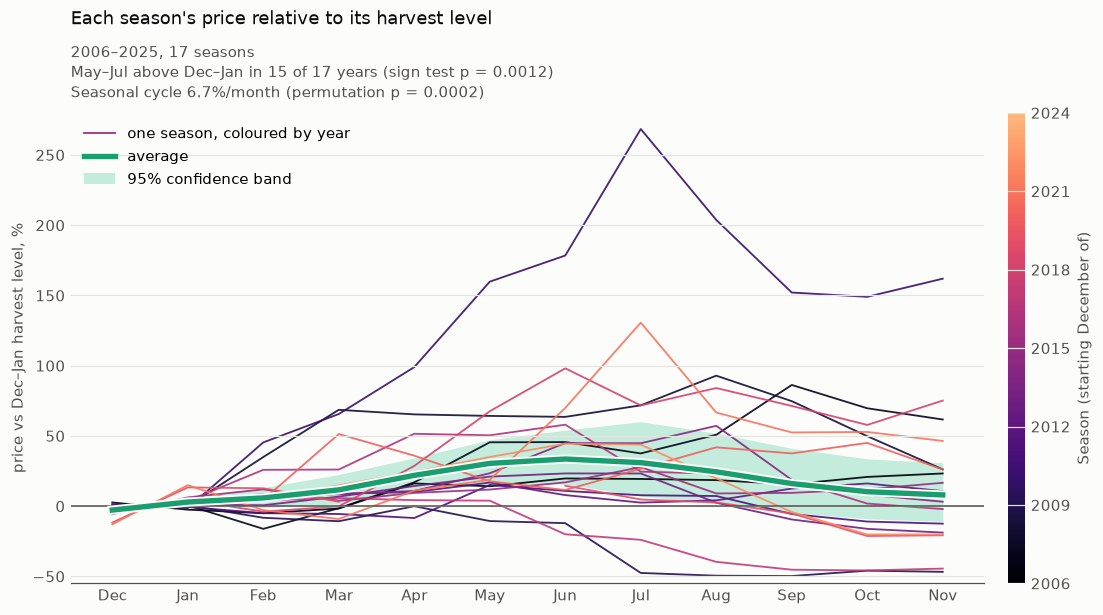

Kruskal-Wallis p                 0.000023
ANOVA p                          0.000081
annual cycle, %/month            6.674546
permutation p                      0.0002
seasons up Dec-Jan -> May-Jul       15/17
sign test p                      0.001175
dtype: object

In [5]:
res = season.run_tests(price, np.random.default_rng(2026))

fig, ax = plt.subplots(figsize=(11, 6.2))
top, bottom = season.panel(ax, "Uasin-Gishu", price, res)       # lines coloured by year, average, band
ax.set_ylim(25 * np.floor(bottom / 25) - 5, 25 * np.ceil(top / 25) + 5)
ax.set_ylabel("price vs Dec–Jan harvest level, %")
ax.set_title("Each season's price relative to its harvest level", loc="left", color=INK, pad=58)
ax.grid(axis="x", visible=False)
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
ax.legend(handles=[Line2D([], [], color=season.SEASON_CMAP(0.55), lw=1.2, label="one season, coloured by year"),
                   Line2D([], [], color=season.AVG, lw=3.5, label="average"),
                   Patch(facecolor=season.AVG_BAND, label="95% confidence band")],
          loc="upper left", frameon=False)
fig.subplots_adjust(right=0.88, top=0.8)
pos = ax.get_position()
season.season_colorbar(fig, fig.add_axes([0.9, pos.y0, 0.014, pos.height]))
plt.show()

pd.Series({"Kruskal-Wallis p": res["kw_p"], "ANOVA p": res["anova_p"],
           "annual cycle, %/month": 100 * res["amp"], "permutation p": res["amp_p"],
           "seasons up Dec-Jan -> May-Jul": f"{res['pos']}/{len(res['rises'])}",
           "sign test p": res["sign_p"]})

**Average price change by calendar month.** Mean log return into each month with standard
errors from `qk.mc_estimate` (each month's returns treated as a sample).

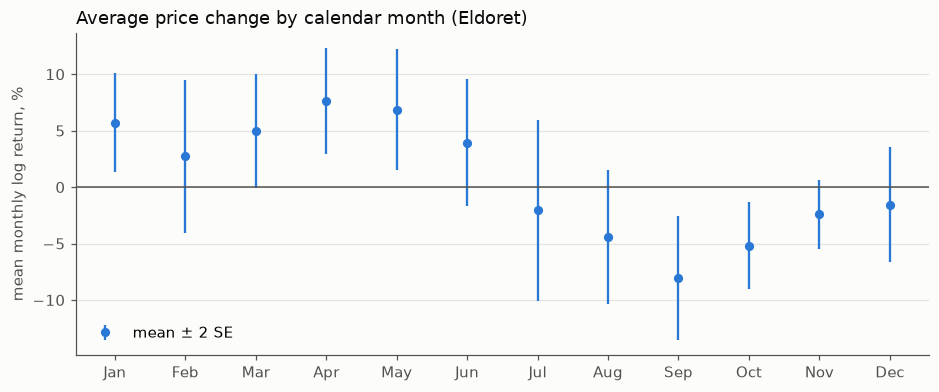

,n,mean,se
month,,,
Jan,17,0.0572,0.0220
Feb,18,0.0273,0.0340
Mar,19,0.0494,0.0253
Apr,18,0.0762,0.0236
May,19,0.0684,0.0269
Jun,19,0.0393,0.0282
Jul,19,-0.0207,0.0402
Aug,19,-0.0446,0.0297
Sep,19,-0.0805,0.0276


In [6]:
rows = []
for m in range(1, 13):
    x = r[r.index.month == m].values
    mean, se = qk.mc_estimate(x)
    rows.append({"month": MONTHS[m - 1], "n": len(x), "mean": mean, "se": se})
mm = pd.DataFrame(rows).set_index("month")

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.errorbar(np.arange(12), 100 * mm["mean"], yerr=200 * mm["se"], fmt="o", ms=5, color=BLUE,
            capsize=0, lw=1.5, label="mean ± 2 SE")
ax.axhline(0, color=INK2, lw=1)
ax.set_xticks(range(12), MONTHS); ax.set_ylabel("mean monthly log return, %")
ax.set_title("Average price change by calendar month (Eldoret)", loc="left", color=INK)
ax.legend(frameon=False, loc="lower left"); ax.grid(axis="x", visible=False)
plt.show()
mm.round(4)

**Reading.** Prices fall from August to December (harvest arriving) and rise from January to
June (stocks running down). The cycle is significant in every test, and the price was higher in
May–July than at the December–January harvest level in 15 of 17 seasons. Storage has a reason
to exist; the question for Steps 6–8 is whether the rise beats interest, fees and losses after
accounting for the bad years (the two seasons where it fell).

## Step 3 — Seasonal drift (Lecture 4; least-squares calibration as in F26 L12)

Twelve separate monthly means are noisy (each rests on ≈ 17–19 returns). We smooth them with
a few annual harmonics,

$$ g(m) = a + \sum_{k=1}^{K} \Big[ b_k \sin\tfrac{2\pi k m}{12} + c_k \cos\tfrac{2\pi k m}{12} \Big], $$

where $g(m)$ is the expected log return **into** calendar month $m$. The coefficients are
fitted with `scipy.optimize.least_squares`, the same tool Lecture 12 uses to calibrate Heston.
$K$ is chosen by **leave-one-year-out cross-validation**: hold out each year, fit on the rest,
and score the squared error on the held-out year.

In [7]:
def design(months, K):
    cols = [np.ones(len(months))]
    for k in range(1, K + 1):
        cols += [np.sin(2 * np.pi * k * months / 12), np.cos(2 * np.pi * k * months / 12)]
    return np.column_stack(cols)

def fit_drift(r, K):
    X, y = design(r.index.month.values, K), r.values
    res = least_squares(lambda beta: X @ beta - y, x0=np.zeros(X.shape[1]))
    return res.x

def g_of(beta, K, months=np.arange(1, 13)):
    return design(months, K) @ beta

def cv_score(r, K):
    err = []
    for yr in sorted(set(r.index.year)):
        tr, te = r[r.index.year != yr], r[r.index.year == yr]
        if K == "12 means":
            pred = tr.groupby(tr.index.month).mean().reindex(te.index.month).values
        else:
            pred = g_of(fit_drift(tr, K), K, te.index.month.values)
        err.append((te.values - pred) ** 2)
    return np.concatenate(err).mean()

cv = pd.Series({(f"K={K}" if K != "12 means" else K): cv_score(r, K) for K in [0, 1, 2, 3, "12 means"]})
(cv / cv["K=0"]).round(4).rename("CV MSE relative to constant drift")

K=0         1.0000
K=1         0.8754
K=2         0.8911
K=3         0.8998
12 means    0.9287
Name: CV MSE relative to constant drift, dtype: float64

chosen K = 1


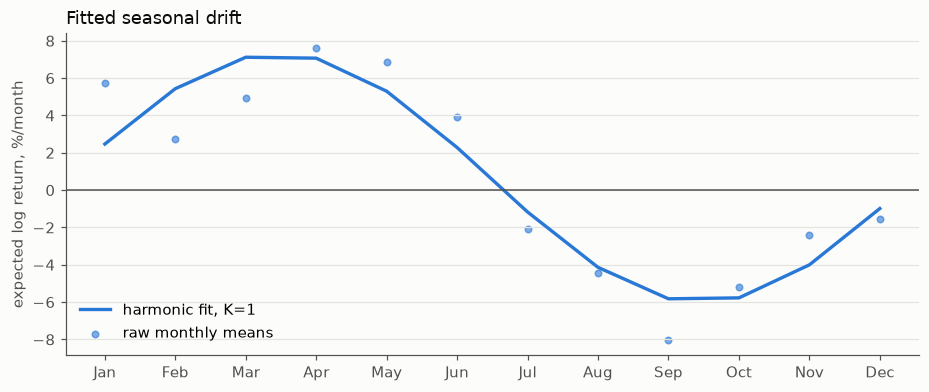

Dec     0.0
Jan     2.5
Feb     8.2
Mar    16.2
Apr    24.7
May    31.5
Jun    34.5
Jul    33.0
Aug    27.6
Name: expected price vs December, %, dtype: float64

In [8]:
K = int(cv.drop("12 means").idxmin().split("=")[1])
print("chosen K =", K)
g = pd.Series(g_of(fit_drift(r, K), K), index=MONTHS)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(range(12), 100 * g.values, color=BLUE, lw=2.2, label=f"harmonic fit, K={K}")
ax.scatter(np.arange(12), 100 * mm["mean"], color=BLUE, s=18, alpha=.6, label="raw monthly means")
ax.axhline(0, color=INK2, lw=1)
ax.set_xticks(range(12), MONTHS); ax.set_ylabel("expected log return, %/month")
ax.set_title("Fitted seasonal drift", loc="left", color=INK)
ax.legend(frameon=False, loc="lower left"); ax.grid(axis="x", visible=False)
plt.show()

# implied average seasonal path from December (the storage start), as % above December
path = 100 * (np.exp(np.cumsum(np.r_[0, g[MONTHS[:8]].values])) - 1)
pd.Series(path, index=["Dec"] + MONTHS[:8]).round(1).rename("expected price vs December, %")

## Step 4 — Volatility and the GBM assumptions (Lectures 3a, 8, 11b)

### 4a. Raw returns

GBM assumes i.i.d. normal log returns. First on the raw returns: normality, autocorrelation of
returns (momentum / mean reversion) and of absolute returns (volatility clustering).

In [9]:
nt = qk.test_normality(r)
lb = qk.ljung_box(r.values, lags=12)
lba = qk.ljung_box(np.abs(r.values), lags=12)
pd.Series({"n returns": len(r), "mean (annualized)": 12 * r.mean(),
           "volatility (annualized)": qk.annualized_vol(r, periods_per_year=12),
           "skew": nt["skewness"], "excess kurtosis": nt["excess_kurtosis"],
           "normality p (D'Agostino)": nt["p_dagostino"], "normality p (Shapiro)": nt["p_shapiro"],
           "Ljung-Box r, 12 lags p": lb["lb_pvalue"][-1],
           "Ljung-Box |r|, 12 lags p": lba["lb_pvalue"][-1]}).round(4)

n returns                   220.0000
mean (annualized)             0.0773
volatility (annualized)       0.4338
skew                         -0.0208
excess kurtosis               1.7887
normality p (D'Agostino)      0.0020
normality p (Shapiro)         0.0000
Ljung-Box r, 12 lags p        0.0039
Ljung-Box |r|, 12 lags p      0.4642
dtype: float64

Ljung–Box on raw returns at 12 lags partly picks up the **seasonal cycle itself** (returns in
the same calendar month are alike). The honest test of the i.i.d. assumption is on returns
*after* removing the seasonal drift $g(m)$ from Step 3.

### 4b. De-seasonalized returns and σ

The residuals $\varepsilon_t = r_t - g(m_t)$ are what GBM treats as i.i.d. normal shocks. Their
standard deviation is the model's $\sigma$.

In [10]:
eps = r - g.values[r.index.month - 1]
sigma = qk.annualized_vol(eps, periods_per_year=12)
nt, lb, lba = qk.test_normality(eps), qk.ljung_box(eps.values, 12), qk.ljung_box(np.abs(eps.values), 12)
display(pd.Series({"sigma (annualized)": sigma, "raw vol (annualized)": qk.annualized_vol(r, 12),
                   "excess kurtosis": nt["excess_kurtosis"], "normality p (Shapiro)": nt["p_shapiro"],
                   "Ljung-Box eps, 12 lags p": lb["lb_pvalue"][-1],
                   "Ljung-Box |eps|, 12 lags p": lba["lb_pvalue"][-1]}).round(4))

# autocorrelation by lag on the calendar-aligned series (gaps stay NaN, so pairs are only
# formed between months that are exactly L apart)
eps_cal = eps.reindex(full)
acf = pd.Series({L: eps_cal.corr(eps_cal.shift(L)) for L in range(1, 13)})
print(f"autocorrelation of eps by lag (approx. 95% noise band ±{2 / np.sqrt(len(eps)):.2f}):")
acf.round(2).to_frame("acf").T

sigma (annualized)            0.4014
raw vol (annualized)          0.4338
excess kurtosis               1.8288
normality p (Shapiro)         0.0002
Ljung-Box eps, 12 lags p      0.0015
Ljung-Box |eps|, 12 lags p    0.0104
dtype: float64

autocorrelation of eps by lag (approx. 95% noise band ±0.13):


,1,2,3,4,5,6,7,8,9,10,11,12
acf,0.05,-0.03,-0.08,-0.04,0.18,0.14,-0.12,-0.08,-0.03,0.02,-0.05,-0.21


**Reading.** Removing the seasonal drift takes σ from ≈ 0.43 down to ≈ 0.40: part of the "raw"
volatility was the predictable cycle. What is left is **not** i.i.d. normal:

* **fat tails** (excess kurtosis ≈ 2; normality rejected): large monthly moves are more common
  than GBM allows;
* **no month-to-month momentum** (lag-1 autocorrelation ≈ 0.05), but **negative autocorrelation
  at lag 12** (≈ −0.2, outside the noise band) — this is what makes Ljung–Box reject. A month
  that was unusually strong one year tends to be weak in the same month the next year:
  year-to-year mean reversion, e.g. a shortage year followed by a recovery harvest. (Smaller
  positive values at lags 5–6, ≈ +0.15, are borderline.) Two consequences: the seasonal drift
  varies from year to year around the average estimated here, and Step 5's baseline "last
  year's same-month change" should forecast *badly*;
* **volatility clustering** (Ljung–Box on |ε| rejects): calm and turbulent stretches.

These are the main ways the GBM-based option value can be wrong. They are tested directly in
Step 8 (the backtest uses real paths, not GBM) and in the Step 10 model-risk extension
(regime-switching or Heston volatility).

### 4c. Volatility over time

Volatility over the **past 12 calendar months**, annualized: the standard deviation of the
monthly returns observed in that year × √12, computed only when at least 9 of the 12 returns
exist. Months with no price are shaded grey; windows that contain a gap (9–11 returns) are
drawn dotted, so every point means "the past year" but the less certain ones are visible.
Both the raw and the de-seasonalized returns are shown; dashed lines are full-sample values.

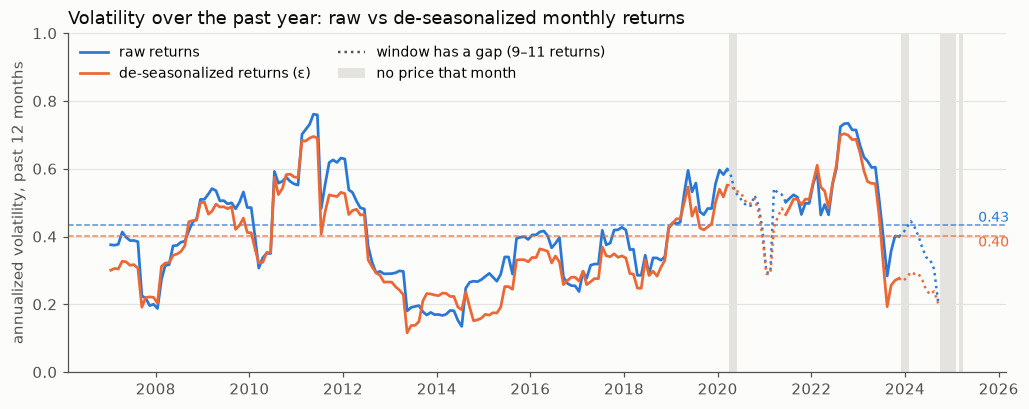

windows with a gap (9–11 returns): 24, in years [2020, 2021, 2023, 2024]
windows not computed (< 9 returns): 9: 2024-10 -> 2025-06
median: raw 0.405, de-seasonalized 0.343; max 0.76 (2011-05), min 0.13 (2014-07)
years with the highest de-seasonalized volatility: {2022: 0.7, 2011: 0.7, 2023: 0.65, 2010: 0.58, 2020: 0.55}


,n,vol
month,,
"Mar–Apr, Sep–Oct",74,0.358
harvest Nov–Feb,70,0.366
lean May–Aug,76,0.470


In [11]:
MIN_RET = 9
def vol_past_year(x):
    xc = x.reindex(full)
    vol = xc.rolling(12, min_periods=MIN_RET).std() * np.sqrt(12)
    n = xc.rolling(12, min_periods=1).count()
    vol.iloc[:11] = np.nan                  # first 11 months: less than a year of history, not a gap
    n.iloc[:11] = np.nan
    return vol, n

rv, n_ret = vol_past_year(r)
rv_eps, _ = vol_past_year(eps)
t = full.to_timestamp() + pd.Timedelta(days=14)

fig, ax = plt.subplots(figsize=(11, 4))
for m in price[price.isna()].index:                                  # grey = no price that month
    d = m.to_timestamp() + pd.Timedelta(days=14)
    ax.axvspan(d - pd.Timedelta(days=15), d + pd.Timedelta(days=15), color=GRID, lw=0, zorder=0)
complete = (n_ret == 12).values
handles = []
for series, level, col, lab, va in [(rv, qk.annualized_vol(r, 12), BLUE, "raw returns", "bottom"),
                                    (rv_eps, sigma, ORANGE, "de-seasonalized returns (ε)", "top")]:
    v = series.values
    solid = np.where(complete, v, np.nan)
    # dotted where the window has a gap; extend one point so solid and dotted segments join
    gap = complete == False
    gap_ext = gap | np.r_[gap[1:], False] | np.r_[False, gap[:-1]]
    dotted = np.where(gap_ext, v, np.nan)
    handles.append(ax.plot(t, solid, color=col, lw=1.8, label=lab)[0])
    ax.plot(t, dotted, color=col, lw=1.6, ls=":")
    ax.axhline(level, color=col, lw=1, ls="--", alpha=.8)
    ax.text(t[-1] + pd.Timedelta(days=40), level, f"{level:.2f}", color=col, va=va, fontsize=9)
handles += [Line2D([], [], color=INK2, lw=1.6, ls=":", label=f"window has a gap ({MIN_RET}–11 returns)"),
            Patch(facecolor=GRID, label="no price that month")]
ax.set_ylabel("annualized volatility, past 12 months")
ax.set_title("Volatility over the past year: raw vs de-seasonalized monthly returns", loc="left", color=INK)
ax.set_ylim(0, 1.0)                                                   # headroom for the legend
ax.legend(handles=handles, frameon=False, loc="upper left", ncol=2, fontsize=9)
ax.grid(axis="x", visible=False)
ax.xaxis.set_major_locator(mdates.YearLocator(2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.show()

gap_years = sorted({p.year for p in full[(n_ret.values < 12) & (n_ret.values >= MIN_RET)]})
too_few = full[(n_ret.values < MIN_RET) & (np.arange(len(full)) >= 11)]
print(f"windows with a gap ({MIN_RET}–11 returns): {int(((n_ret < 12) & (n_ret >= MIN_RET)).sum())}, in years {gap_years}")
print(f"windows not computed (< {MIN_RET} returns): {len(too_few)}: {too_few.min()} -> {too_few.max()}" if len(too_few) else "none")
print(f"median: raw {rv.median():.3f}, de-seasonalized {rv_eps.median():.3f}; "
      f"max {rv.max():.2f} ({rv.idxmax()}), min {rv.min():.2f} ({rv.idxmin()})")
top_years = rv_eps.groupby(rv_eps.index.year).max().sort_values(ascending=False)
print("years with the highest de-seasonalized volatility:", {int(y): round(v, 2) for y, v in top_years.head(5).items()})

# volatility by season (de-seasonalized): harvest/early storage (Nov-Feb), lean (May-Aug), other
season_of = lambda m: "harvest Nov–Feb" if m in (11, 12, 1, 2) else ("lean May–Aug" if m in (5, 6, 7, 8) else "Mar–Apr, Sep–Oct")
eps.groupby(eps.index.month.map(season_of)).agg(n="count", vol=lambda x: x.std() * np.sqrt(12)).round(3)

**Reading.** Volatility is large (≈ 0.40/yr after removing the cycle; a broad stock index is
typically 0.15–0.20) and far from constant: calm and crisis periods alternate (peak years printed
above). The two lines pick out the same periods; the de-seasonalized one usually sits lower
because part of the raw estimate is the predictable seasonal swing. By season, the shocks are
largest in the lean months (May–Aug) — exactly when a storer still holding grain is exposed —
and smallest around harvest. The 2024–25 gaps leave too few returns for a one-year estimate at
the end of the series; the line stops rather than reaching back into 2023.

### 4d. From log drift to the drift the tree and `gbm_paths` need

$g(m)$ is an expected **log** return. `qk.gbm_paths` and `qk.binomial_optimal_stopping` take an
**arithmetic** growth rate $\mu$ with $E[S_{t+dt}/S_t] = e^{\mu\,dt}$. Under GBM the two differ
by the Itô term:

$$ \mu(m) = 12\,g(m) + \tfrac{1}{2}\sigma^2 . $$

Leaving out $\tfrac12\sigma^2$ (≈ 8%/yr here, since σ ≈ 0.4) would understate the expected
price path by that much and bias the storage value down.

### 4e. Does the model reproduce history? (simulation check)

For every historical month $t$ with prices at $t$ and $t+h$ ($h$ = 3 and 6 months), simulate
the model from the same calendar month with `qk.gbm_paths` and ask whether the realized log
change falls inside the simulated 5–95% band. A well-calibrated model covers ≈ 90%.

In [12]:
mu = 12 * g + 0.5 * sigma ** 2            # arithmetic drift into each calendar month, annualized

def simulate_log_change(start_month, h, n_sims=20_000, k=4):
    # start_month: 0-based index = calendar month mod 12, so step i ends in MONTHS[(start_month + i) % 12]
    mu_path = np.repeat(mu.values[[(start_month + i) % 12 for i in range(h)]], k)
    S = qk.gbm_paths(1.0, sigma, h / 12, 0.0, h * k, n_sims, mu=mu_path, rng=rng)
    return np.log(S[:, -1])

lp = np.log(price)
coverage = []
for h in (3, 6):
    bands = {m0: np.quantile(simulate_log_change(m0, h), [.05, .95]) for m0 in range(12)}
    realized = (lp.shift(-h) - lp).dropna()
    inside = [bands[p.month % 12][0] <= x <= bands[p.month % 12][1] for p, x in realized.items()]
    coverage.append({"horizon (months)": h, "n windows": len(inside),
                     "share inside 5–95% band": np.mean(inside)})
pd.DataFrame(coverage).set_index("horizon (months)").round(3)

,n windows,share inside 5–95% band
horizon (months),,
3,215,0.893
6,212,0.896


Note on the indexing: a step that ends in calendar month $m$ uses $\mu(m)$, matching how
$g(m)$ was fitted (the return *into* month $m$). Starting at month $m_0$ (0-based index =
calendar month mod 12), the first step ends in month $m_0+1$.

### 4f. Optional: two volatility regimes (Lecture 11b)

Using the de-seasonalized past-year volatility from 4c, classify each month as high-volatility
when it is above its median, estimate the mean duration of each regime, and convert to
switching rates $\alpha$ (calm → crisis) and $\beta$ (crisis → calm) per year for
`qk.markov_vol_states`. Months where the past-year volatility could not be computed are not
classified.

In [13]:
v = rv_eps.dropna()
high = (v > v.median()).astype(int)
runs = (high != high.shift()).cumsum()
durations = high.groupby(runs).agg(["first", "size"])
mean_dur = durations.groupby("first")["size"].mean() / 12          # years
alpha, beta_rate = 1 / mean_dur[0], 1 / mean_dur[1]
regime = high.reindex(eps.index)
sig_lo = eps[regime == 0].std() * np.sqrt(12)
sig_hi = eps[regime == 1].std() * np.sqrt(12)
print(f"classified months: {int(regime.notna().sum())} of {len(eps)} returns")
print(f"mean duration: calm {mean_dur[0]:.2f} yr, crisis {mean_dur[1]:.2f} yr  ->  alpha={alpha:.2f}/yr, beta={beta_rate:.2f}/yr")
print(f"sigma calm = {sig_lo:.3f}, sigma crisis = {sig_hi:.3f} (single-regime sigma = {sigma:.3f})")

classified months: 207 of 220 returns
mean duration: calm 1.11 yr, crisis 1.26 yr  ->  alpha=0.90/yr, beta=0.79/yr
sigma calm = 0.273, sigma crisis = 0.506 (single-regime sigma = 0.401)


These regime parameters are saved for the model-risk extension (Step 10). Because "high"
is defined from a one-year window, regimes are persistent by construction; treat the
durations as rough.

### 4g. Save the model for Steps 5–9

In [14]:
params = {"window": [str(price.index.min()), str(price.index.max())], "K": K, "sigma": sigma,
          "g_log_monthly": g.to_dict(), "mu_arith_annual": mu.to_dict(),
          "regimes": {"alpha": alpha, "beta": beta_rate, "sigma_calm": sig_lo, "sigma_crisis": sig_hi}}
Path("data/processed/model_params.json").write_text(json.dumps(params, indent=2))
mu.round(3).rename("mu(m), annualized")

Jan    0.376
Feb    0.733
Mar    0.935
Apr    0.929
May    0.716
Jun    0.354
Jul   -0.060
Aug   -0.416
Sep   -0.618
Oct   -0.612
Nov   -0.400
Dec   -0.038
Name: mu(m), annualized, dtype: float64

## Summary of Steps 1–4

* **Data:** 225 of 234 months of Eldoret wholesale prices, 2006-01 → 2025-06, nominal KSh/kg.
* **Seasonality:** strong and stable — falling August → December, rising January → June,
  significant in every test; up from harvest to May–July in 15 of 17 seasons.
* **Model:** seasonal log drift $g(m)$ (harmonics, $K$ by cross-validation) + constant σ ≈ 0.40,
  with arithmetic drift $\mu(m) = 12g(m) + \sigma^2/2$ for the tree. Saved to
  `data/processed/model_params.json`.
* **Volatility:** ≈ 0.40/yr after removing the cycle, clearly time-varying (calm vs crisis
  years), largest in the lean season.
* **GBM assumptions:** shocks have fat tails, no month-to-month momentum but year-to-year mean
  reversion (lag-12 autocorrelation ≈ −0.2), and volatility clustering. GBM is an
  approximation; Steps 8 and 10 measure what that costs.
* **Coverage check:** realized 3- and 6-month price changes fall inside the model's 5–95% band
  ≈ 89–90% of the time (target 90%).

**Next (Steps 5–9):** out-of-sample forecast check of $g(m)$; the storage option value and sell
rule with `qk.binomial_optimal_stopping` (warehouse vs on-farm); Monte Carlo check; historical
backtest; sensitivities.